# WELL-E formal comparison

MI, EMSE, and Adaptive WIVR ran on three Gazebo scenarios with one shared synthetic field and one mission per policy and scenario. The mission budget includes the return to Home. The GP starts with zero observations and a fixed prior mean of 25 degrees Celsius. It uses the fitted RBF length scales, signal variance, and measurement noise.

The main accuracy metric is the final GP reconstruction RMSE on the fixed 2 m / 5 s spatiotemporal grid. Only accepted missions enter the formal ranking. The A/MI row also reports a supplemental overtime score on the same grid. Its final GP contains 300 valid observations through 300.00 s.


In [1]:
RUN = 'formal_all_runs'
from pathlib import Path
import html
import json
import statistics
import numpy as np
from IPython.display import HTML, display

root = Path.cwd()
shared = root / "results" / RUN
evaluation = json.loads((shared / "evaluation.json").read_text())
overtime = json.loads((shared / "overtime_rmse.json").read_text())
setup = json.loads((shared / "shared" / "initial.json").read_text())
folders = {"A": "Baseline Test A", "B": "Test B", "C": "Test C"}
policies = {"mi": "MI", "emse": "EMSE", "wivr": "Adaptive WIVR"}
budgets = {case: json.loads((shared / "scenarios" / case / "scenario.json").read_text())["mission_budget_s"]
           for case in folders}
entries = {}
for case, folder in folders.items():
    for policy in policies:
        directory = root / folder / "results" / RUN / policy
        status = json.loads((directory / "run_status.json").read_text())
        mission = status.get("mission_summary", {})
        searches = [json.loads(path.read_text()) for path in directory.glob("plan_*.json")]
        initial = directory / "initial_plan.json"
        plans = [p["seconds"] for p in searches]
        entries[case, policy] = {
            "directory": directory,
            "status": status["status"],
            "mission": mission,
            "rmse": evaluation[case][policy].get("domains", {}),
            "p95": float(np.percentile(plans, 95)) if plans else None,
            "median": statistics.median(plans) if plans else None,
            "timeouts": sum(p["timeout"] for p in searches),
            "initial_s": json.loads(initial.read_text())["seconds"] if initial.is_file() else None,
        }

def show_table(headers, rows):
    def line(values, tag):
        return "<tr>" + "".join(f"<{tag}>{html.escape(str(v))}</{tag}>" for v in values) + "</tr>"
    display(HTML("<table>" + line(headers, "th") + "".join(line(r, "td") for r in rows) + "</table>"))

def number(value, digits=2):
    return "" if value is None or value == -1 else f"{value:.{digits}f}"

def rmse(entry, domain):
    if entry is entries[overtime["scenario"], overtime["policy"]]:
        value = overtime["domains"][domain]["rmse_c"]
        return f"{value:.5f} (overtime +{overtime['overrun_s']:.2f} s)"
    return number(entry["rmse"].get(domain, {}).get("rmse_c"), 5)

assert len(entries) == 9 and setup["mean"] == 25.0 and setup["x"] == setup["y"] == []
print("Comparison:", RUN)
print("RBF length scales (m, m, s):", setup["length"])
print("Signal and noise variance (deg C squared):", setup["variance"], setup["noise"])

show_table(
    ["Case", "Policy", "Status", "Home arrival (s)", "Budget (s)", "Samples", "Return samples",
     "Full RMSE (deg C)", "Initial search (s)", "GRG median (s)", "GRG P95 (s)", "GRG timeouts"],
    [[case, policies[policy], e["status"], number(e["mission"].get("home_arrival_t")),
      budgets[case], e["mission"].get("measurements", ""), e["mission"].get("return_measurements", ""),
      rmse(e, "full"), number(e["initial_s"], 3), number(e["median"], 3), number(e["p95"], 3), e["timeouts"]]
     for (case, policy), e in entries.items()],
)

Comparison: formal_all_runs
RBF length scales (m, m, s): [6.247029284656602, 44.102937277740494, 37.93368188870053]
Signal and noise variance (deg C squared): 0.47980997033896927 0.0008420943803521325


Case,Policy,Status,Home arrival (s),Budget (s),Samples,Return samples,Full RMSE (deg C),Initial search (s),GRG median (s),GRG P95 (s),GRG timeouts
A,MI,overtime,301.25,300,300,22,0.18869 (overtime +1.25 s),0.011,0.016,0.035,0
A,EMSE,accepted,295.28,300,295,8,0.16390,0.518,0.404,0.698,0
A,Adaptive WIVR,accepted,295.02,300,295,8,0.16368,0.460,0.385,0.629,0
B,MI,accepted,140.04,150,140,8,0.28173,0.014,0.006,0.014,0
B,EMSE,accepted,143.02,150,143,29,0.23794,0.273,0.130,0.225,0
B,Adaptive WIVR,accepted,144.03,150,144,6,0.20693,0.274,0.052,0.224,0
C,MI,accepted,287.35,300,287,12,0.69849,0.049,0.026,0.058,0
C,EMSE,accepted,281.77,300,281,12,0.70015,7.755,0.645,5.084,0
C,Adaptive WIVR,accepted,288.55,300,288,12,0.74529,7.834,0.089,4.361,0


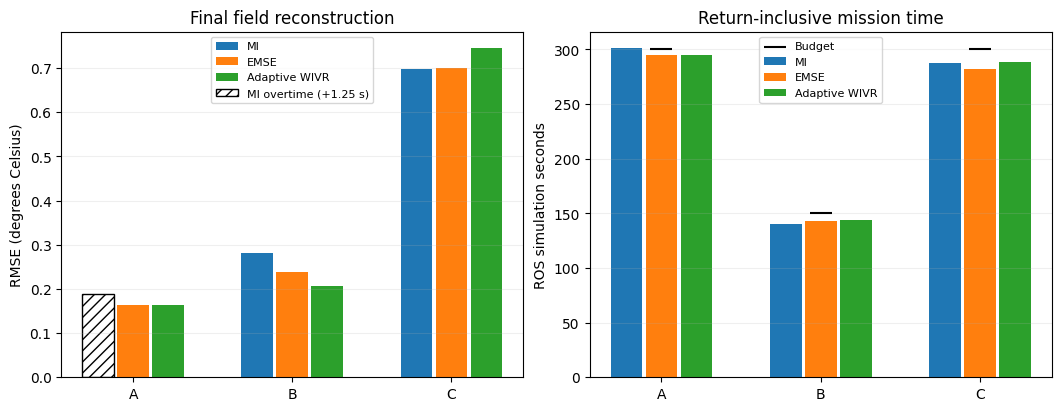

In [2]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4), layout="constrained")
for j, (policy, label) in enumerate(policies.items()):
    x = np.arange(3) + (j - 1) * 0.22
    scores = [entries[case, policy]["rmse"].get("full", {}).get("rmse_c", np.nan) for case in folders]
    completion = [entries[case, policy]["mission"].get("home_arrival_t", -1) for case in folders]
    cart = [v if v >= 0 else np.nan for v in completion]
    axes[0].bar(x, scores, width=0.20, label=label)
    axes[1].bar(x, cart, width=0.20, label=label)
axes[0].bar(-0.22, overtime["domains"]["full"]["rmse_c"], width=0.20,
            facecolor="white", edgecolor="black", hatch="///", label="MI overtime (+1.25 s)")
axes[0].set(title="Final field reconstruction", ylabel="RMSE (degrees Celsius)")
axes[1].set(title="Return-inclusive mission time", ylabel="ROS simulation seconds")
axes[1].scatter(range(3), [budgets[c] for c in folders], color="black", marker="_",
                s=250, label="Budget", zorder=5)
for ax in axes:
    ax.set_xticks(range(3), list(folders))
    ax.grid(axis="y", alpha=0.2)
    ax.legend(fontsize=8)
plt.show()

## Evaluations on matched domains

A and B share the original field and the 0–150 s evaluation interval. The A result is its final posterior after a 300 s budget. A and C share the original 30 m × 20 m field and the 0–300 s interval. The added-area score evaluates the part of C outside that original footprint. The per-scenario full scores summarize each scenario on its own domain.


In [3]:
show_table(
    ["Policy", "A, 0–150 s", "B, 0–150 s", "A, small region", "C, same region", "C, added area"],
    [[label, rmse(entries["A", policy], "common_time"), rmse(entries["B", policy], "common_time"),
      rmse(entries["A", policy], "common_space"), rmse(entries["C", policy], "common_space"),
      rmse(entries["C", policy], "added_area")]
     for policy, label in policies.items()],
)
for case in folders:
    scores = [(policy, entries[case, policy]["rmse"]["full"]["rmse_c"])
              for policy in policies if "full" in entries[case, policy]["rmse"]]
    if scores:
        winner, error = min(scores, key=lambda item: item[1])
        print(f"{case}: lowest reported full-domain RMSE is {error:.5f} deg C ({policies[winner]}).")
    failures = [f"{policies[p]} ({entries[case, p]['status']})" for p in policies
                if entries[case, p]["status"] != "accepted"]
    if failures:
        print(f"  Outcomes excluded from the formal ranking: {', '.join(failures)}.")

Policy,"A, 0–150 s","B, 0–150 s","A, small region","C, same region","C, added area"
MI,0.14328 (overtime +1.25 s),0.28173,0.18869 (overtime +1.25 s),0.50546,0.75190
EMSE,0.14641,0.23794,0.16390,0.52263,0.75004
Adaptive WIVR,0.14523,0.20693,0.16368,0.42742,0.82445


A: lowest reported full-domain RMSE is 0.16368 deg C (Adaptive WIVR).
  Outcomes excluded from the formal ranking: MI (overtime).
B: lowest reported full-domain RMSE is 0.20693 deg C (Adaptive WIVR).
C: lowest reported full-domain RMSE is 0.69849 deg C (MI).


## Reconstruction over time and sampling coverage

Each 5 s slice uses the **final** posterior and the nominal 2 m grid. The sample-count axis reports how many measurements had been collected by the slice time. These are retrospective errors, so later measurements can contribute. Only accepted missions have error or uncertainty curves. The second figure traces actual sampled poses. The dotted line shows return samples. Predicted and actual leg totals use matched, completed goal–arrival pairs, including Home. Container peak memory is sampled at 1 Hz.

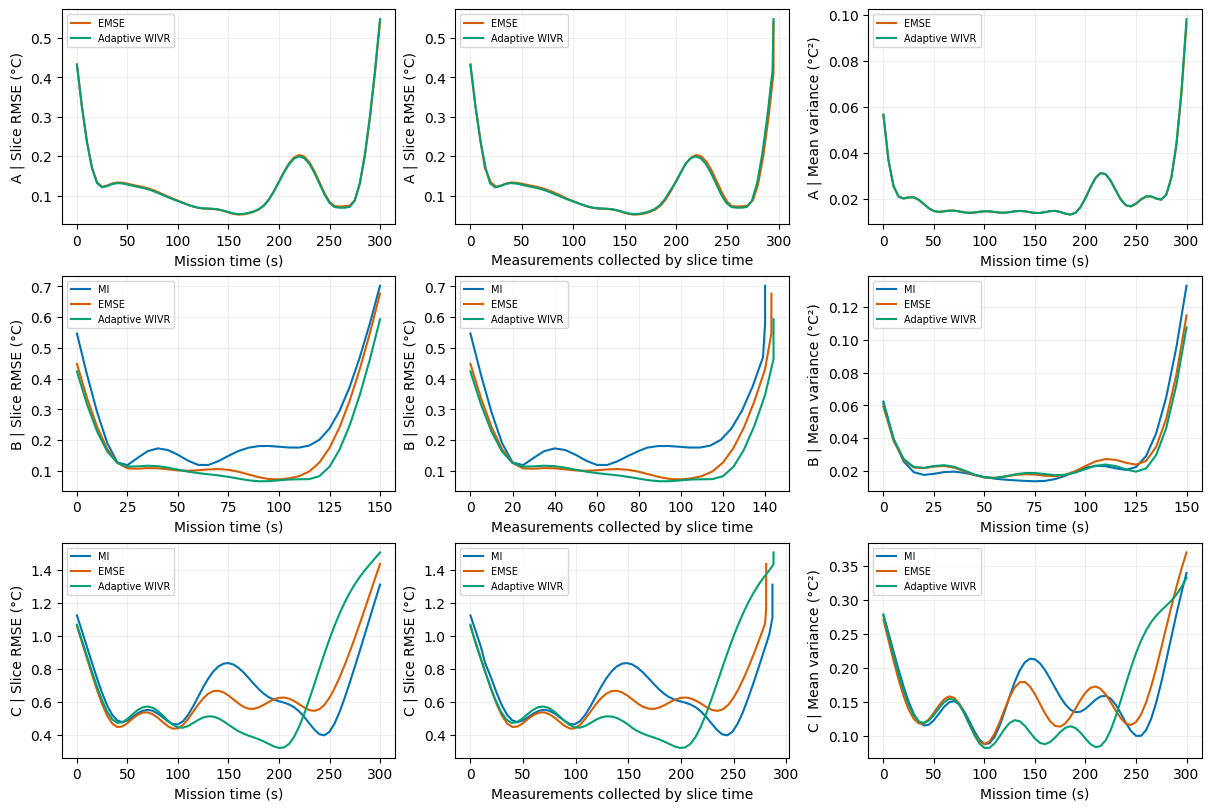

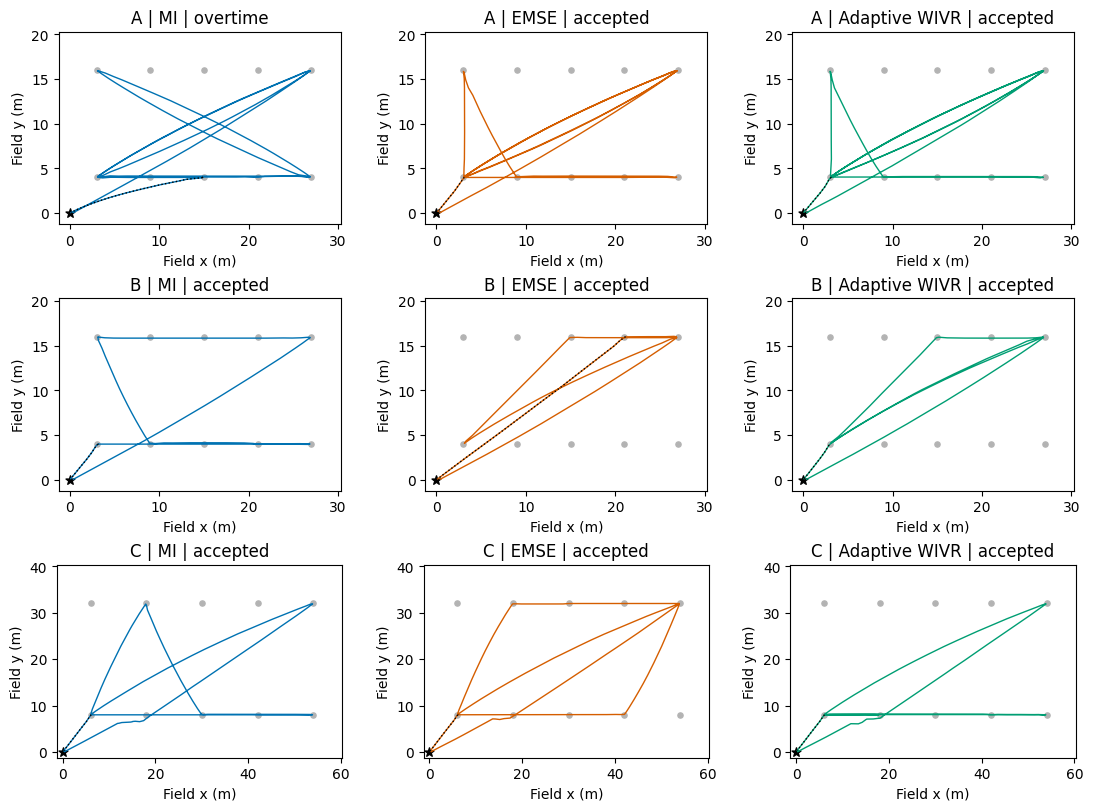

Case,Policy,Visited / nominal 2 m cells,Additional readings in visited cells,Missed ticks,Median interval (s),Predicted leg sum (s),Actual leg sum (s),Arrival wait (s),GP update P95 (ms),Peak container GiB
A,MI,60/150,240,0,1.000,300.29,301.14,0.10,1.161,1.57
A,EMSE,54/150,241,0,1.000,296.81,295.18,0.09,1.383,1.70
A,Adaptive WIVR,51/150,244,0,1.000,296.81,294.93,0.08,1.223,1.70
B,MI,53/150,87,0,1.000,151.57,139.97,0.06,0.199,1.57
B,EMSE,46/150,97,0,1.000,150.40,142.97,0.04,0.191,1.64
B,Adaptive WIVR,43/150,101,0,1.000,149.78,143.98,0.04,0.198,1.64
C,MI,122/600,165,0,1.000,304.90,287.28,0.06,1.022,1.63
C,EMSE,133/600,148,0,1.000,307.60,281.70,0.06,0.937,2.16
C,Adaptive WIVR,91/600,197,0,1.000,298.49,288.48,0.05,0.933,2.16


In [4]:
import math
slices = json.loads((shared/"reconstruction_slices.json").read_text())
colors = {"mi":"#0072B2","emse":"#D55E00","wivr":"#009E73"}
details = []
fig, axes = plt.subplots(3, 3, figsize=(12, 8), layout="constrained")
for row, case in enumerate(folders):
    for policy, label in policies.items():
        item=entries[case,policy]
        slice_rows=slices[case].get(policy, [])
        if slice_rows:
            stamp=[p["t"] for p in slice_rows]
            error=[p["rmse"] for p in slice_rows]
            for axis, xx, yy in [(0,stamp,error), (1,[p["observations"] for p in slice_rows],error), (2,stamp,[p["mean_latent_variance"] for p in slice_rows])]:
                axes[row,axis].plot(xx,yy,label=label,color=colors[policy])
    for col,axis in enumerate(axes[row]):
        axis.set_xlabel("Measurements collected by slice time" if col==1 else "Mission time (s)")
        axis.set_ylabel(f"{case} | "+("Mean variance (°C²)" if col==2 else "Slice RMSE (°C)"))
        axis.grid(alpha=.2)
        if axis.lines: axis.legend(fontsize=7)
plt.show()
fig,axes=plt.subplots(3,3,figsize=(11,8),layout="constrained")
for r,(case,folder) in enumerate(folders.items()):
    for c,(policy,label) in enumerate(policies.items()):
        item=entries[case,policy]
        path=item["directory"]
        events=[json.loads(line) for line in (path/"events.jsonl").read_text().splitlines()] if (path/"events.jsonl").exists() else []
        temps=[e for e in events if e["event"]=="temperature" and e.get("ok")]
        poses=[e for e in events if e["event"]=="query"]
        candidates=np.array(json.loads((path/"candidates.json").read_text()))
        ax=axes[r,c]
        ax.scatter(*candidates[1:].T,color="0.7",s=14)
        ax.scatter(0,0,marker="*",color="black",s=45)
        if poses: ax.plot([p["x"] for p in poses],[p["y"] for p in poses],lw=1,color=colors[policy])
        ret=[p for p in poses if p["returning"]]
        if ret: ax.plot([p["x"] for p in ret],[p["y"] for p in ret],color="black",ls=":",lw=1)
        ax.set(title=case+" | "+label+" | "+item["status"],xlabel="Field x (m)",ylabel="Field y (m)",aspect="equal")
        extent=json.loads((shared/"scenarios"/case/"scenario.json").read_text())["extent_m"]
        ax.set_xlim(-1.25,extent[0]+.3); ax.set_ylim(-1.25,extent[1]+.3)
        cell_visits=[(int(t["x"]//2),int(t["y"]//2)) for t in temps if 0<=t["x"]<extent[0] and 0<=t["y"]<extent[1]]
        graph_file=path/"graph.json"
        graph={(e["from"],e["to"]):e["duration_s"] for e in json.loads(graph_file.read_text())} if graph_file.exists() else {}
        legs={}; anchor=0; pred=[]; actual=[]
        for e in events:
            if e["event"]=="nav_goal":
                legs[e["goal_epoch"]]=(anchor,e["target"],e["event_t"])
            if e["event"]=="arrived" and e["goal_epoch"] in legs:
                a,b,t=legs[e["goal_epoch"]]; anchor=b
                if (a,b) in graph: pred.append(graph[a,b]); actual.append(e["event_t"]-t)
        lat=[e["seconds"]*1000 for e in events if e["event"]=="gp_update"]
        m=item["mission"]
        mem_file=path/"resources.jsonl"
        mem=[json.loads(line)["container_memory_bytes"]/2**30 for line in mem_file.read_text().splitlines()] if mem_file.exists() else []
        dt=np.diff([t["t"] for t in temps])
        details.append([case,label,str(len(set(cell_visits)))+"/"+str((extent[0]//2)*(extent[1]//2)),len(cell_visits)-len(set(cell_visits)),m.get("missed_ticks",""),number(float(np.median(dt)) if len(dt) else None,3),number(sum(pred)),number(sum(actual)),number(m.get("arrival_wait_s")),number(float(np.percentile(lat,95)) if lat else None,3),number(max(mem) if mem else None,2)])
plt.show()
show_table(["Case","Policy","Visited / nominal 2 m cells","Additional readings in visited cells","Missed ticks","Median interval (s)","Predicted leg sum (s)","Actual leg sum (s)","Arrival wait (s)","GP update P95 (ms)","Peak container GiB"],details)

The rankings summarize one realization and one run per method. ROS simulation time measures return-inclusive mission duration. GRG search times are wall-clock measurements of individual searches. Mission, event, and plan records are stored with each policy's output and the shared evaluator output is under the comparison name.
